# Sales Prediction Using Python
**Goal:** predict product sales from advertising spend on TV, Radio and Newspaper.

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [37]:
df = pd.read_csv('Advertising.csv')
df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [38]:
df = df.drop(columns='Unnamed: 0')

print("Shape:", df.shape)
print()
print(df.dtypes)
print()
print("Missing values:")
print(df.isnull().sum())

Shape: (200, 4)

TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

Missing values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


In [39]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [40]:
from sklearn.model_selection import train_test_split

X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

Training rows: 160 | Testing rows: 40


In [41]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained")

Linear Regression trained
Random Forest trained


In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []
for name, model in models.items():
    preds = model.predict(X_test)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, preds),
        "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "R2": r2_score(y_test, preds),
    })

results_df = pd.DataFrame(results).round(3)
results_df

,Model,MAE,RMSE,R2
0,Linear Regression,1.461,1.782,0.899
1,Random Forest,0.619,0.766,0.981


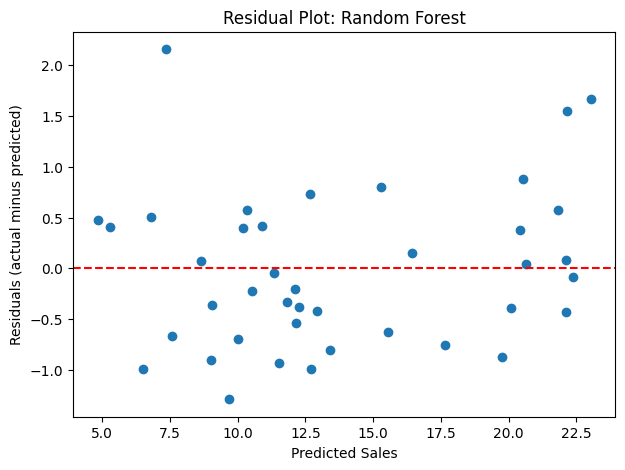

In [43]:
best_name = "Random Forest"
best_model = models[best_name]

preds = best_model.predict(X_test)
residuals = y_test - preds

plt.figure(figsize=(7, 5))
plt.scatter(preds, residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Sales')
plt.ylabel('Residuals (actual minus predicted)')
plt.title(f'Residual Plot: {best_name}')
plt.show()

In [44]:
coef_df = pd.DataFrame({
    "Channel": X.columns,
    "Coefficient": models["Linear Regression"].coef_
}).round(4)
coef_df

,Channel,Coefficient
0,TV,0.0447
1,Radio,0.1892
2,Newspaper,0.0028


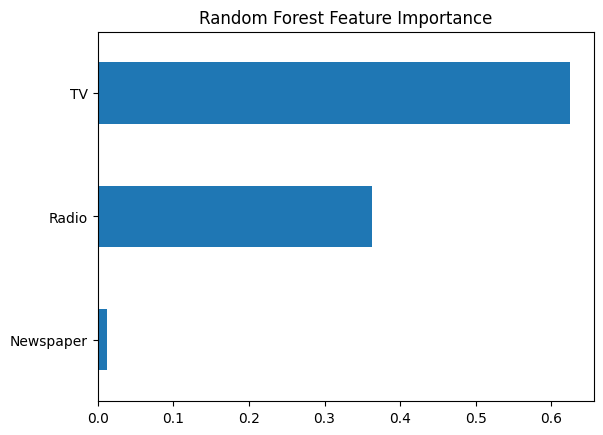

In [45]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind='barh', title='Random Forest Feature Importance')
plt.show()

### Model Comparison
| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression | 1.461 | 1.782 | 0.899 |
| Random Forest | 0.619 | 0.766 | 0.981 |

**Best model: Random Forest.** It has the lowest error (MAE 0.619, RMSE 0.766) and the highest R² (0.981), so its predictions sit closest to actual sales. Linear Regression is still a decent baseline, explaining about 90% of the variation in sales.

### Residual Analysis
The Random Forest residuals are scattered around zero with no clear pattern, which suggests the model fits well. One point has a larger error (about 2 units), but nothing is systematic. For comparison, the Linear Regression residuals form a U-shaped curve, which means the linear model misses a non-linear pattern in the data.

### Which channel has the biggest impact?
- **TV** has the strongest correlation with Sales (0.782), followed by Radio (0.576).
- **Radio** has the largest coefficient in the linear model (0.1892), so each extra unit spent on Radio adds about 0.19 units of sales. TV's coefficient is smaller per unit (0.0447), but TV budgets are much bigger, which is why it correlates most strongly with sales overall.
- **Newspaper** has a coefficient close to zero (0.0028) and the weakest correlation (0.228), so it adds almost nothing once TV and Radio are accounted for.

**Conclusion:** TV and Radio drive sales, while Newspaper spend appears to have little effect. A business with a limited budget should prioritise TV and Radio.

In [46]:
print("MODEL RESULTS")
print(results_df.to_string(index=False))
print()
print("CORRELATION WITH SALES")
print(df.corr()['Sales'].round(3))
print()
print("LINEAR REGRESSION COEFFICIENTS")
print(coef_df.to_string(index=False))

MODEL RESULTS
            Model   MAE  RMSE    R2
Linear Regression 1.461 1.782 0.899
    Random Forest 0.619 0.766 0.981

CORRELATION WITH SALES
TV           0.782
Radio        0.576
Newspaper    0.228
Sales        1.000
Name: Sales, dtype: float64

LINEAR REGRESSION COEFFICIENTS
  Channel  Coefficient
       TV       0.0447
    Radio       0.1892
Newspaper       0.0028
